# 00 — Course guide and setup

| | |
| --- | --- |
| **Prerequisites** | Basic Python: variables, functions, lists, loops |
| **You will learn** | How the course is organized; how to run notebooks locally or on Colab; CPU, CUDA, and MPS devices; why results vary between runs and machines, and how to control it |
| **Estimated time** | 1–1.5 hours |
| **Compute** | CPU. One optional GPU cell. |

## Setup

Every notebook starts with the same setup cell. It makes the course's helper package, `dlcourse`, importable, applies the plot style, prints your software and hardware, and picks a **device** — the hardware PyTorch will compute on. Run it now.

In [1]:
# Setup: make the course helpers importable and record the environment.
import sys
from pathlib import Path

try:
    import dlcourse
except ImportError:  # running without `uv sync`, e.g. on Colab after cloning the repo
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlcourse").is_dir())
    sys.path.insert(0, str(root))
    import dlcourse

import matplotlib.pyplot as plt
import torch

from dlcourse import check, check_close, check_shape, passed, set_seed
from dlcourse.plotting import setup_style

setup_style()
device = dlcourse.describe_environment()
set_seed(0)

Python  3.12.13 (Darwin arm64)
PyTorch 2.14.1
CUDA available: False
MPS available:  True
Selected device: mps


The printed versions matter. When you compare your results with someone else's, or with the numbers in the text, differences in PyTorch version or hardware can explain small numerical differences. Section 4 shows why.

## 1. How this course works

The course has 11 chapters. Each chapter is a sequence of **teaching notebooks** followed by a **problem set**. Each notebook answers one question and ends by naming a problem it leaves unsolved — that problem motivates the next notebook.

You practice at three levels:

1. **Inline checkpoints** — short tasks right after each idea, with an automatic check.
2. **End-of-notebook exercises** — in four kinds, always in this order:
   - *Modify:* change existing code and explain what happens.
   - *Implement:* write something from scratch; a check compares it with a reference.
   - *Debug:* fix code that is deliberately broken.
   - *Investigate:* answer an open question with an experiment and a short written conclusion.
3. **Chapter problem sets** — larger problems that combine a whole chapter.

Each notebook exists in two versions: the one in `notebooks/` (exercises blank) and the one in `solutions/` (worked solutions). Hints are inside the notebooks, collapsed. Try each exercise before opening a hint, and open a hint before opening a solution.

### How exercises and checks work

An exercise cell contains `raise NotImplementedError` where your code goes. Replace those two lines with your answer and run the cell. Then run the **check** cell after it: it either prints ✅ or raises an `AssertionError` that says what is wrong.

Try it now. Set `answer` to the number of chapters in the course.

In [2]:
answer = 11

In [3]:
check(answer == 11, f"answer is {answer}; the course has one more chapter than ten")
passed("Warm-up")

✅ Warm-up passed


The check helpers you will see most are:

- `check(condition, message)` — fails with `message` if `condition` is false.
- `check_shape(tensor, expected_shape)` — compares a tensor's shape.
- `check_close(actual, expected)` — compares numbers or tensors up to a small tolerance. Section 4 explains why exact equality is the wrong test for floating-point results.

## 2. Running the notebooks

### Locally (recommended)

The repository uses [uv](https://docs.astral.sh/uv/) to install pinned versions of Python and every package:

```bash
uv sync                 # create .venv with the exact versions in uv.lock
uv run jupyter lab      # open the notebooks
```

### On Google Colab (for a free GPU)

Colab already has PyTorch installed. Choose **Runtime → Change runtime type → GPU**, then in the first cell:

```python
!git clone https://github.com/sumilk/deep-learning-with-pytorch.git
%cd deep-learning-with-pytorch/notebooks/ch01_foundations
```

The setup cell finds the `dlcourse` package from there. Colab's PyTorch version may differ from the pinned one; the printed versions tell you if it does.

### The fresh-kernel rule

A notebook remembers every variable from every cell you have run, in whatever order you ran them. That **hidden state** causes bugs that disappear when someone else runs the notebook. Before trusting a result, use **Kernel → Restart Kernel and Run All Cells**. Every notebook in this course is tested this way.

A small demonstration of hidden state. Imagine you ran these two cells, then edited the first to `scale = 3` but forgot to re-run it:

In [4]:
scale = 2

In [5]:
values = [1, 2, 3]
scaled = [scale * v for v in values]
scaled

[2, 4, 6]

The second cell would still use `scale = 2`, while the notebook *shows* `scale = 3`. The output on screen no longer matches the code on screen. Restart-and-run-all is the only reliable fix.

## 3. Devices: CPU, CUDA, and MPS

PyTorch can compute on several kinds of hardware, called **devices**:

| Device | Hardware | Notes |
| --- | --- | --- |
| `cpu` | Your computer's processor | Always available. All core labs run here. |
| `cuda` | NVIDIA GPUs | The main GPU platform for deep learning. Available on Colab and most cloud machines. |
| `mps` | Apple Silicon GPUs (M1 and later) | Fast for many operations, but some operations and data types are unsupported. |

A GPU runs thousands of simple arithmetic operations at once. Deep learning is mostly large matrix multiplications, which split into many independent multiply-adds, so it benefits enormously — once the problem is big enough. For the small problems in early chapters, the CPU is often just as fast. Chapter 5 measures exactly when a GPU helps.

`dlcourse.get_device()` chooses CUDA if available, then MPS, then CPU. You can override the choice by setting the environment variable `DLCOURSE_DEVICE` (for example `DLCOURSE_DEVICE=cpu`) before starting Jupyter.

A tensor lives on exactly one device. Create it there directly with `device=`, or move it with `.to(device)`:

In [6]:
x_cpu = torch.tensor([1.0, 2.0, 3.0])
x_dev = x_cpu.to(device)
y_dev = torch.ones(3, device=device)

print("x_cpu is on", x_cpu.device)
print("x_dev is on", x_dev.device)
print("x_dev + y_dev =", (x_dev + y_dev).cpu())

x_cpu is on cpu
x_dev is on mps:0
x_dev + y_dev = tensor([2., 3., 4.])


Operations require all their tensors on the same device. Combining tensors from different devices is an error, not an automatic copy. If your selected device is a GPU, this cell shows the error; on a CPU-only machine there is nothing to mix.

In [7]:
if device.type == "cpu":
    print("Only the CPU is available here, so there is no cross-device error to show.")
else:
    try:
        x_cpu + y_dev
    except RuntimeError as error:
        print("RuntimeError:", str(error).splitlines()[0])

RuntimeError: Expected all tensors to be on the same device, but found at least two devices, mps:0 and cpu!


**MPS caveat.** Apple's MPS backend does not support 64-bit floats (`float64`). Deep learning rarely needs them, but some numerical checks in this course do; those checks run on the CPU.

In [8]:
if device.type == "mps":
    try:
        torch.zeros(2, dtype=torch.float64, device=device)
    except (TypeError, RuntimeError) as error:
        print(type(error).__name__ + ":", str(error).splitlines()[0])
else:
    print(f"Not on MPS (device is {device}); float64 works:", torch.zeros(2, dtype=torch.float64, device=device))

TypeError: Cannot convert a MPS Tensor to float64 dtype as the MPS framework doesn't support float64. Please use float32 instead.


### Checkpoint 3.1

Create `z`: a tensor of zeros with 2 rows and 3 columns, **on the selected `device`**.

<details>
<summary><b>💡 Hint</b></summary>

Most tensor-creating functions accept a `device=` keyword: `torch.zeros(rows, cols, device=...)`.

</details>

In [9]:
z = torch.zeros(2, 3, device=device)

In [10]:
check_shape(z, (2, 3), "z")
check(z.device.type == device.type, f"z is on {z.device}, expected {device}")
check(bool((z == 0).all()), "z should contain only zeros")
passed("Checkpoint 3.1")

✅ Checkpoint 3.1 passed


## 4. Reproducibility

Training a neural network involves randomness: initial weights, the order of training examples, dropout. Two runs of the same code can therefore give different results. To make a result reproducible, we fix the **seed** of the random number generator.

A pseudo-random generator produces a long, fixed sequence of numbers determined entirely by its seed. Same seed, same sequence:

In [11]:
torch.manual_seed(42)
a = torch.rand(3)
torch.manual_seed(42)
b = torch.rand(3)
c = torch.rand(3)  # the generator has moved on

print("a =", a)
print("b =", b, "(same seed → same numbers)")
print("c =", c, "(next numbers in the sequence)")

a = tensor([0.8823, 0.9150, 0.3829])
b = tensor([0.8823, 0.9150, 0.3829]) (same seed → same numbers)
c = tensor([0.9593, 0.3904, 0.6009]) (next numbers in the sequence)


`dlcourse.set_seed(seed)` seeds Python's `random`, NumPy, and PyTorch together, because libraries you use may draw from any of them.

Seeding the *global* generator has a weakness: any extra random call anywhere shifts every later number. A dedicated `torch.Generator` isolates one source of randomness from the rest of the program:

In [12]:
gen = torch.Generator().manual_seed(123)
first = torch.rand(3, generator=gen)

_ = torch.rand(1000)  # unrelated global randomness elsewhere in the program

gen = torch.Generator().manual_seed(123)
second = torch.rand(3, generator=gen)
print(first, second, torch.equal(first, second))

tensor([0.2961, 0.5166, 0.2517]) tensor([0.2961, 0.5166, 0.2517]) True


### Seeds are not enough: floating-point arithmetic

Computers store real numbers as **floating-point** numbers with limited precision. A `float32` has about 7 significant decimal digits. Each addition rounds its result, so the *order* of additions changes the answer:

In [13]:
t = torch.tensor([1e8, 1.0, -1e8], dtype=torch.float32)
left_to_right = (t[0] + t[1]) + t[2]   # 1e8 + 1 rounds back to 1e8, so the 1 is lost
reordered = (t[0] + t[2]) + t[1]       # 1e8 - 1e8 = 0, then + 1
print("(1e8 + 1) - 1e8 =", left_to_right.item())
print("(1e8 - 1e8) + 1 =", reordered.item())

(1e8 + 1) - 1e8 = 0.0
(1e8 - 1e8) + 1 = 1.0


Addition of floating-point numbers is **not associative**. Different hardware — or the same GPU running a parallel sum in a different order — can add numbers in different orders and get slightly different results, even with identical seeds.

Consequences for this course:

- Compare floating-point results with a tolerance (`check_close`, `torch.allclose`), never with `==`.
- Tiny differences between machines are expected. A large difference signals a bug.
- For full determinism on one machine, `set_seed(seed, deterministic=True)` makes PyTorch use deterministic algorithms where they exist, and raise an error where they don't. It can be slower.
- Even then, results can still differ across hardware and PyTorch versions.

### Checkpoint 4.1

Using a `torch.Generator` seeded with `7`, draw 5 numbers with `torch.randn` and store them in `draw1`. Then do the same again, from a fresh generator with the same seed, into `draw2`.

<details>
<summary><b>💡 Hint</b></summary>

`torch.randn(5, generator=torch.Generator().manual_seed(7))` creates a fresh generator inline.

</details>

In [14]:
draw1 = torch.randn(5, generator=torch.Generator().manual_seed(7))
draw2 = torch.randn(5, generator=torch.Generator().manual_seed(7))

In [15]:
check_shape(draw1, (5,), "draw1")
check_shape(draw2, (5,), "draw2")
check(torch.equal(draw1, draw2), "draw1 and draw2 should be identical: use two fresh generators with the same seed")
check_close(draw1, torch.randn(5, generator=torch.Generator().manual_seed(7)), "draw1")
passed("Checkpoint 4.1")

✅ Checkpoint 4.1 passed


## 5. [GPU] The same computation on two devices

If you have a GPU, this cell multiplies the same matrices on the CPU and on the GPU and reports the largest difference. Each entry of a matrix product is a sum of 512 products, and the two devices may add them in different orders. On CUDA GPUs the difference is usually small but nonzero; on some hardware it happens to be exactly zero. Either way, a tolerance-based comparison is the right test. On a CPU-only machine the cell skips itself.

In [16]:
if device.type == "cpu":
    print("No GPU selected; skipping. (Set up Colab with a GPU runtime to try this.)")
else:
    gen = torch.Generator().manual_seed(0)
    A = torch.randn(512, 512, generator=gen)
    B = torch.randn(512, 512, generator=gen)
    on_cpu = A @ B
    on_gpu = (A.to(device) @ B.to(device)).cpu()
    diff = (on_cpu - on_gpu).abs().max().item()
    print(f"Largest |CPU − {device.type.upper()}| difference: {diff:.2e}")
    print("allclose with rtol=atol=1e-4:", torch.allclose(on_cpu, on_gpu, rtol=1e-4, atol=1e-4))

Largest |CPU − MPS| difference: 0.00e+00
allclose with rtol=atol=1e-4: True


## Exercises

### Exercise 1 (modify): seeds and sequences

Run the cell below, then change the seed from `0` to `1` and run it again. Which of the three printed results change, and which stay the same? Write your answer in the markdown cell below the code.

In [17]:
set_seed(0)
print("global draw:   ", torch.rand(2))
print("generator draw:", torch.rand(2, generator=torch.Generator().manual_seed(99)))
print("constant:      ", torch.ones(2))

global draw:    tensor([0.4963, 0.7682])
generator draw: tensor([0.1033, 0.9702])
constant:       tensor([1., 1.])


*Your answer:*

> **Worked solution.**
>
> Only the global draw changes. The generator draw uses its own generator seeded with `99`, which `set_seed` does not touch. `torch.ones` involves no randomness.

### Exercise 2 (implement): reproducible draws

Write `reproducible_normal(seed, n)` that returns `n` standard-normal samples that depend **only** on `seed` — not on any other random calls the program has made.

<details>
<summary><b>💡 Hint</b></summary>

Create a `torch.Generator`, seed it, and pass it to `torch.randn` with the `generator=` keyword. Do not use `torch.manual_seed`, which changes global state.

</details>

In [18]:
def reproducible_normal(seed, n):
    gen = torch.Generator().manual_seed(seed)
    return torch.randn(n, generator=gen)

In [19]:
first = reproducible_normal(3, 4)
torch.rand(10)  # unrelated randomness must not affect the result
second = reproducible_normal(3, 4)
check_shape(first, (4,), "reproducible_normal(3, 4)")
check(torch.equal(first, second), "the same seed must give the same numbers, regardless of other random calls")
check(not torch.equal(first, reproducible_normal(4, 4)), "different seeds should give different numbers")
state = torch.get_rng_state()
reproducible_normal(5, 3)
check(torch.equal(state, torch.get_rng_state()), "reproducible_normal must not change the global random state")
passed("Exercise 2")

✅ Exercise 2 passed


### Exercise 3 (debug): a seed that does not work

This function is supposed to return the same weights every time it is called, but it does not. Find and fix the bug.

<details>
<summary><b>💡 Hint</b></summary>

Look at *when* the seed is set relative to the random draw.

</details>

In [20]:
def make_weights():
    # Buggy version:
    #     weights = torch.randn(3)
    #     torch.manual_seed(0)
    #     return weights
    torch.manual_seed(0)
    weights = torch.randn(3)
    return weights

In [21]:
check(torch.equal(make_weights(), make_weights()), "make_weights() should return identical tensors on every call")
passed("Exercise 3")

✅ Exercise 3 passed


### Exercise 4 (investigate): how large are rounding errors?

Section 4 showed that the order of additions changes a floating-point sum. How large is the effect for realistic data, and does the way we add numbers up matter?

The scaffold below sums `n` random numbers stored as `float32` in two ways, and compares each with an accurate `float64` reference:

- **Running sum:** add the numbers one at a time, left to right (`numpy.cumsum` does exactly this).
- **`torch.sum`:** PyTorch's built-in reduction, which adds numbers in a tree-like order: pairs first, then pairs of pairs.

1. Run it and look at the plot.
2. Change `dtype` to `torch.float64` and run it again (the reference stays the same).
3. In the markdown cell below, describe how each error grows with `n`, and explain why the running sum is worse.

<details>
<summary><b>💡 Hint</b></summary>

In a running sum, the total quickly becomes much larger than each new term. Think about how many significant digits of a small number survive when it is added to a large one — and how many additions each number takes part in.

</details>

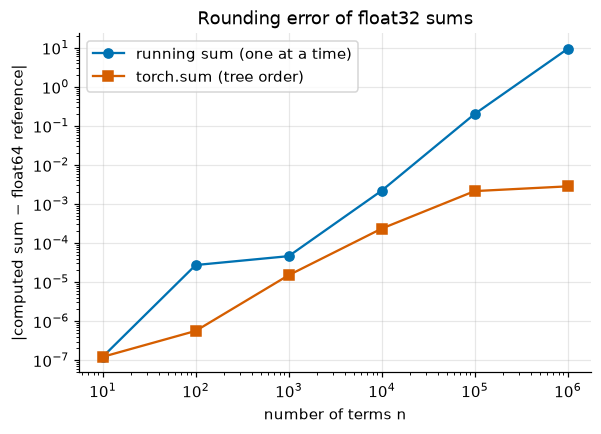

n =        10   running-sum error 1.2e-07   torch.sum error 1.2e-07
n =       100   running-sum error 2.7e-05   torch.sum error 5.6e-07
n =     1,000   running-sum error 4.6e-05   torch.sum error 1.5e-05
n =    10,000   running-sum error 2.2e-03   torch.sum error 2.3e-04
n =   100,000   running-sum error 2.0e-01   torch.sum error 2.1e-03
n = 1,000,000   running-sum error 9.4e+00   torch.sum error 2.8e-03


In [22]:
import numpy as np

dtype = torch.float32
sizes = [10, 100, 1_000, 10_000, 100_000, 1_000_000]
running_errors, torch_errors = [], []
gen = torch.Generator().manual_seed(0)
for n in sizes:
    exact = torch.rand(n, generator=gen, dtype=torch.float64)
    values = exact.to(dtype)
    reference = exact.sum().item()
    running = np.cumsum(values.numpy())[-1].item()  # one at a time, left to right
    torch_errors.append(abs(values.sum().item() - reference))
    running_errors.append(abs(running - reference))

plt.loglog(sizes, running_errors, "o-", label="running sum (one at a time)")
plt.loglog(sizes, torch_errors, "s-", label="torch.sum (tree order)")
plt.xlabel("number of terms n")
plt.ylabel("|computed sum − float64 reference|")
plt.title(f"Rounding error of {str(dtype).replace('torch.', '')} sums")
plt.legend()
plt.show()
for n, r, t in zip(sizes, running_errors, torch_errors):
    print(f"n = {n:>9,}   running-sum error {r:.1e}   torch.sum error {t:.1e}")

*Your conclusion:*

> **Worked solution.**
>
> In `float32`, the running-sum error grows rapidly with `n`: about 2e-3 at ten thousand terms, and about 9 at a million. The sum is about 500,000, so only its first five digits are right. `torch.sum` stays far more accurate, with errors around 1e-3 at a million terms. A running sum adds each new number to an ever-larger total; `float32` keeps only about 7 significant digits, so the low digits of each small term are rounded away, and every number suffers this in each of the up to `n` additions. Tree-order summation adds numbers of similar size and each number takes part in only about log₂ n additions, so errors grow far more slowly. In `float64`, both errors drop by many orders of magnitude, because `float64` keeps about 16 significant digits. Lessons: the algorithm matters as much as the precision, and comparison tolerances must reflect both.

## Summary and what's next

- The course moves from tensors to Transformers. Each notebook has inline checkpoints and end-of-notebook exercises, and each chapter ends with a problem set.
- Run notebooks top to bottom from a fresh kernel; hidden state makes results untrustworthy.
- PyTorch computes on a **device**: `cpu`, `cuda`, or `mps`. Tensors in one operation must share a device.
- Seeds make randomness repeatable. A dedicated `torch.Generator` isolates one source of randomness.
- Floating-point addition is not associative, so compare results with tolerances.

Everything in deep learning is computed on **tensors**. Notebook 01 starts from first principles: what a tensor is, how its shape works, and how PyTorch stores it in memory.